In [1]:
import pandas as pd

df = pd.read_csv("archive.zip")
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
checks = {
    "Missing values": df.isnull().sum().sum(),
    "Duplicate rows": df.duplicated().sum(),
    "Negative amounts": (df["Amount"] < 0).sum(),
    "Amount above 10000": (df["Amount"] > 10000).sum(),
}

report = pd.DataFrame(list(checks.items()),
                      columns=["Check", "Issues found"])
report["Status"] = report["Issues found"].apply(
    lambda n: "PASS" if n == 0 else "FAIL")

print(report)

                Check  Issues found Status
0      Missing values             0   PASS
1      Duplicate rows          1081   FAIL
2    Negative amounts             0   PASS
3  Amount above 10000             7   FAIL


In [3]:
!pip install openpyxl -q
report.to_excel("data_quality_report.xlsx", index=False)
print("Saved")

Saved


In [4]:
clean_df = df.drop_duplicates()
print("Before:", len(df), "After:", len(clean_df))

Before: 284807 After: 283726


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

X = clean_df.drop("Class", axis=1)
y = clean_df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

model = RandomForestClassifier(
    n_estimators=50, class_weight="balanced", n_jobs=-1)
model.fit(X_train, y_train)

print(classification_report(y_test, model.predict(X_test)))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.71      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.85      0.91     56746
weighted avg       1.00      1.00      1.00     56746



In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model2 = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000))
model2.fit(X_train, y_train)

print(classification_report(y_test, model2.predict(X_test)))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



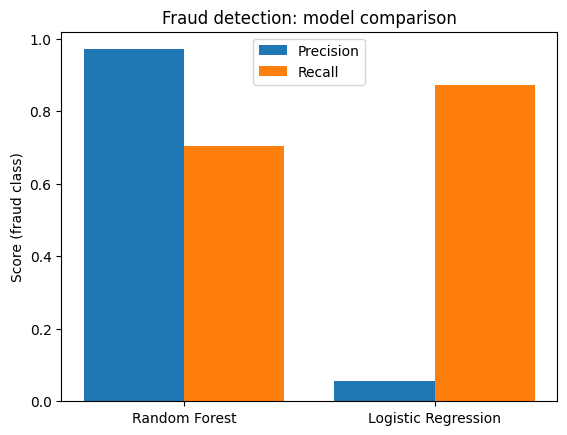

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

names = ["Random Forest", "Logistic Regression"]
preds = [model.predict(X_test), model2.predict(X_test)]

precision = [precision_score(y_test, p) for p in preds]
recall = [recall_score(y_test, p) for p in preds]

x = range(len(names))
plt.bar([i - 0.2 for i in x], precision, width=0.4, label="Precision")
plt.bar([i + 0.2 for i in x], recall, width=0.4, label="Recall")
plt.xticks(x, names)
plt.ylabel("Score (fraud class)")
plt.title("Fraud detection: model comparison")
plt.legend()
plt.savefig("model_comparison.png", dpi=150)
plt.show()